# Day 27 | Read a PDF Before Asking an LLM

**KGP Talkie**

Extract page text, keep page labels, and answer from the supplied text.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

The supplied course uses these v1 interfaces. We keep their version notices out of the classroom display; real input, validation, and server errors still appear.

In [2]:
import warnings
warnings.filterwarnings("ignore", message=".*langchain-community.*sunset.*", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="The class `InMemoryChatMessageHistory` was deprecated.*")

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [3]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [4]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

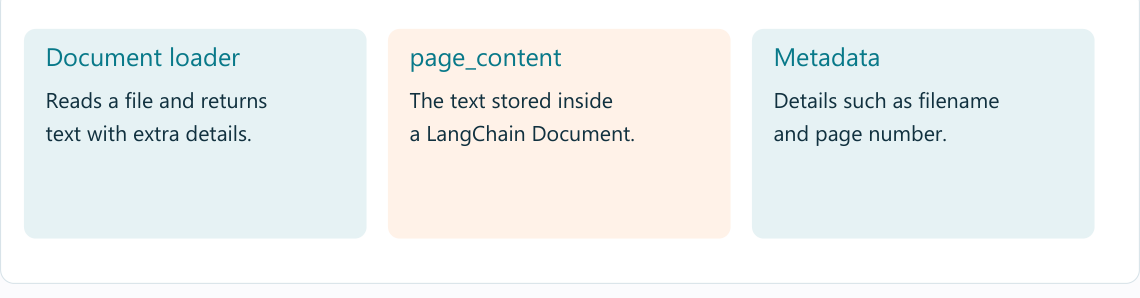

In [5]:
from langchain_community.document_loaders import PyMuPDFLoader

In [6]:
docs = PyMuPDFLoader(str(ASSETS / "timetable.pdf")).load()

In [7]:
print("Pages:", len(docs))
print(docs[1].metadata)

Pages: 2
{'producer': '', 'creator': '', 'creationdate': '', 'source': 'C:\\Users\\Acer\\Downloads\\80 Hour Genai Materials\\.ml-work\\oct09\\ready\\day-27\\assets\\timetable.pdf', 'file_path': 'C:\\Users\\Acer\\Downloads\\80 Hour Genai Materials\\.ml-work\\oct09\\ready\\day-27\\assets\\timetable.pdf', 'total_pages': 2, 'format': 'PDF 1.7', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'moddate': '', 'trapped': '', 'modDate': '', 'creationDate': '', 'page': 1}


In [8]:
print(docs[1].page_content)

Pandas class: Tuesday at 11:00 in Room 3.
No fee is listed in these notes.


Keep every page and a human-readable page label. enumerate starts at 0, so the visible label adds 1.

In [9]:
context = "\n\n".join(f"Page {i + 1}: {doc.page_content}" for i, doc in enumerate(docs))

ChatOllama sends chat requests to the local Ollama server.

In [10]:
from langchain_ollama import ChatOllama

We keep tracing off for the local lesson. KGP_MODEL lets us choose another installed chat tag; llama3.2 is the tested default.

In [11]:
os.environ["LANGSMITH_TRACING"] = "false"
MODEL = os.getenv("KGP_MODEL", "llama3.2")

Temperature 0 reduces varied choices. The 128-token cap keeps this small task short; it does not guarantee correctness. localhost means this computer.

In [12]:
llm = ChatOllama(model=MODEL, temperature=0, num_predict=128, base_url="http://localhost:11434", client_kwargs={"timeout": 180})

In [13]:
question = "When is the Pandas class? Give the page number."

In [14]:
print(llm.invoke(f"Use only this PDF text. If missing, say not provided.\n{context}\nQuestion: {question}").content)

The Pandas class is on Tuesday at 11:00 in Room 3, according to Page 2.


In [15]:
print(llm.invoke(f"Use only this PDF text. If missing, say not provided.\n{context}\nQuestion: What is the course fee?").content)

The course fee is not provided.


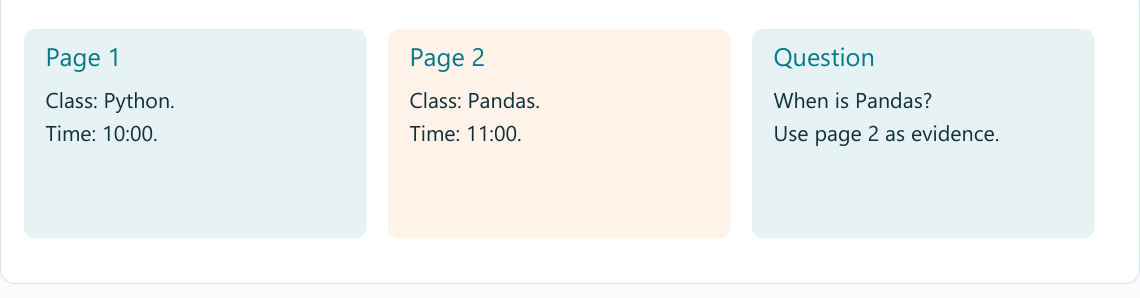

## Try a fresh input

Ask for a fee the PDF never gives. Check whether the answer admits that it is missing.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-document-loaders).